# 06 — Native-resolution residual 2D U-Net

This notebook adds a stronger **classical spatial segmentation candidate** while preserving the original Random Forest baseline and FRQI/NEQR hybrid workflow. It is not a quantum model.

**Important:** the notebook trains only on the training patients, chooses the checkpoint using validation patients, and evaluates the held-out test patients once at the end. It refuses to silently replace a different saved patient split. No performance improvement is guaranteed; only the CSVs generated from your local MSD data can establish that.

In [1]:
from pathlib import Path
import sys, subprocess, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "src"))
DATA_ROOT = ROOT / "data/raw/Task01_BrainTumour"
assert DATA_ROOT.joinpath("dataset.json").is_file(), f"MSD dataset not found: {DATA_ROOT}"
print("Project root:", ROOT)
print("Dataset root:", DATA_ROOT)

Project root: D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION
Dataset root: D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\data\raw\Task01_BrainTumour


In [2]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch: 2.15.0+cpu
CUDA available: False
Device: CPU


## Training configuration

Defaults are a full-cohort training run. For a quick code-path test, use fewer epochs and a smaller batch size, but do not describe a pilot as final performance. The first run builds a local native-resolution slice cache which is not included in the source ZIP.

In [8]:
EPOCHS = 25
BATCH_SIZE = 8
SLICES_PER_PATIENT = 12
BASE_CHANNELS = 16
DEVICE = "auto"  # auto, cpu, cuda
SEED = 42
COMMAND = [sys.executable, str(ROOT / "scripts/train_unet_msd.py"),
    "--epochs", str(EPOCHS), "--batch-size", str(BATCH_SIZE),
    "--slices-per-patient", str(SLICES_PER_PATIENT),
    "--base-channels", str(BASE_CHANNELS), "--device", DEVICE, "--seed", str(SEED)]
print(" ".join(COMMAND))

d:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\.venv\Scripts\python.exe D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\scripts\train_unet_msd.py --epochs 25 --batch-size 8 --slices-per-patient 12 --base-channels 16 --device auto --seed 42


In [9]:
start = time.perf_counter()
completed = subprocess.run(COMMAND, cwd=ROOT, check=True, text=True)
print(f"Training/evaluation wall time:  {time.perf_counter()-start:.1f}s")

CalledProcessError: Command '['d:\\Projects\\CAPSTONE\\QIP\\PROJECT_QUANTUM_V3_SUBMISSION\\.venv\\Scripts\\python.exe', 'D:\\Projects\\CAPSTONE\\QIP\\PROJECT_QUANTUM_V3_SUBMISSION\\scripts\\train_unet_msd.py', '--epochs', '25', '--batch-size', '8', '--slices-per-patient', '12', '--base-channels', '16', '--device', 'auto', '--seed', '42']' returned non-zero exit status 3221225786.

## Validation and held-out test results

The model checkpoint is selected from validation performance only. The test summary below is the final held-out evaluation from the same saved patient split.

In [ ]:
REPORTS = ROOT / "outputs/reports"
val_summary = pd.read_csv(REPORTS / "msd_unet_validation_summary.csv")
test_summary = pd.read_csv(REPORTS / "msd_unet_test_summary.csv")
history = pd.read_csv(REPORTS / "msd_unet_training_history.csv")
display(val_summary)
display(test_summary)
display(history.tail())

,method,resolution,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,macro_iou_present_gt_mean,macro_iou_present_gt_std,...,ET_hd95_pixels_mean,ET_hd95_pixels_std,ET_tp_mean,ET_tp_std,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std
0,UNet2D,240,0.657408,0.234056,0.555433,0.224576,0.689103,0.208611,0.580823,0.207594,...,18.384627,21.238273,320.125,328.251947,215.881944,195.427539,80.368056,122.578803,56983.625,414.451206


,method,resolution,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,macro_iou_present_gt_mean,macro_iou_present_gt_std,...,ET_hd95_pixels_mean,ET_hd95_pixels_std,ET_tp_mean,ET_tp_std,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std
0,UNet2D,240,0.643078,0.231207,0.536737,0.225075,0.668172,0.214769,0.555456,0.214611,...,22.551012,27.673207,304.547297,326.360248,200.067568,202.250927,68.574324,102.358586,57026.810811,397.483793


,epoch,train_loss,validation_active_macro_dice,learning_rate,epoch_seconds
0,1,0.379758,0.656791,0.001,60.48327


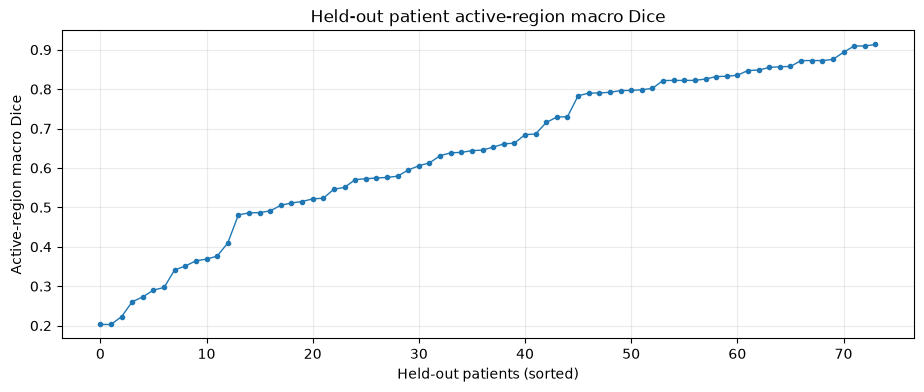

In [6]:
test_per_slice = pd.read_csv(REPORTS / "msd_unet_test_per_slice.csv")
patient_scores = test_per_slice.groupby("patient_id")["macro_dice_active"].mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(np.arange(len(patient_scores)), patient_scores.values, marker=".", linewidth=1)
ax.set(title="Held-out patient active-region macro Dice", xlabel="Held-out patients (sorted)", ylabel="Active-region macro Dice")
ax.grid(True, alpha=0.25)
plt.show()

## Visual spot-check on a held-out case

Choose a case from the held-out test partition. This is a visual quality-control step, not permission to tune the model against test labels.

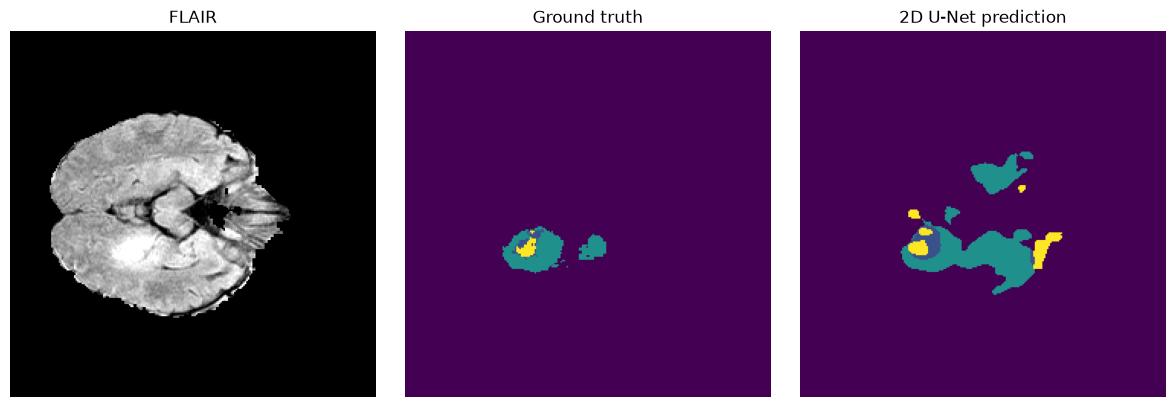

{'case_id': 'BRATS_224', 'slice_index': 53}


In [7]:
from qmi.data.msd_dataset import read_msd_metadata, discover_msd_cases, load_msd_case
from qmi.unet import predict_unet_slice
split = json.loads((REPORTS / "msd_patient_split.json").read_text(encoding="utf-8"))
case_id = split["test"][0]
case_map = {c.case_id: c for c in discover_msd_cases(DATA_ROOT)}
metadata = read_msd_metadata(DATA_ROOT)
modalities, labels = load_msd_case(case_map[case_id], metadata)
# Select the axial slice with the largest labelled tumour area for a meaningful preview.
areas = np.count_nonzero(labels > 0, axis=(1, 2))
z = int(np.argmax(areas))
pred = predict_unet_slice(modalities[:, z], ROOT / "artifacts/msd_unet_240.pt")
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(modalities[0, z], cmap="gray"); axes[0].set_title("FLAIR")
axes[1].imshow(labels[z], vmin=0, vmax=4, cmap="viridis"); axes[1].set_title("Ground truth")
axes[2].imshow(pred, vmin=0, vmax=4, cmap="viridis"); axes[2].set_title("2D U-Net prediction")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print({"case_id": case_id, "slice_index": z})

## Compare with Random Forest fairly

Prefer the generated `msd_unet_vs_rf_paired_test_summary.csv`. It is created only when the saved RF model metadata confirms exactly the same patient-level train/validation/test split, and it evaluates both models on the exact same held-out slices. If the paired report is absent, inspect the printed skip reason in `msd_unet_experiment_summary.json`; do not compare unrelated splits. Check WT/TC/ET Dice and IoU, precision, recall, HD95, empty masks, per-patient variation and overlays.

The Streamlit app exposes this checkpoint under **Dataset & Inference → Residual 2D U-Net**. The Quantum Lab intentionally continues using RF so the FRQI/NEQR experiment remains unchanged.


In [1]:
import sys
import subprocess

print("Python:", sys.executable)

print("\n=== NVIDIA GPU ===")
try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )
    print(result.stdout if result.returncode == 0 else result.stderr)
except FileNotFoundError:
    print("nvidia-smi not found")

print("\n=== PYTORCH CUDA ===")
try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("PyTorch CUDA version:", torch.version.cuda)

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("GPU memory:", round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
        ), "GB")
except Exception as e:
    print("PyTorch error:", repr(e))

Python: d:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\.venv\Scripts\python.exe

=== NVIDIA GPU ===
Fri Nov 13 12:23:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 592.82                 Driver Version: 592.82         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   44C    P8              5W /   30W |       0MiB /   6141MiB |      0%      Default |
|                               

In [2]:
import sys

exc = getattr(sys, "last_value", None)

print("Exception:", repr(exc))

if exc is not None:
    print("\n=== STDOUT ===")
    print(getattr(exc, "stdout", None))

    print("\n=== STDERR ===")
    print(getattr(exc, "stderr", None))

Exception: None


In [3]:
import sys
import subprocess
from pathlib import Path

ROOT = Path(r"D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION")
SCRIPT = ROOT / "scripts" / "train_unet_msd.py"

print("Python:", sys.executable)
print("Script exists:", SCRIPT.exists())

import torch
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

result = subprocess.run(
    [sys.executable, str(SCRIPT), "--help"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print("\n=== TRAINING SCRIPT OPTIONS ===")
print(result.stdout)
if result.stderr:
    print("\n=== STDERR ===")
    print(result.stderr)

print("Exit code:", result.returncode)

Python: d:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\.venv\Scripts\python.exe
Script exists: True
CUDA: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

=== TRAINING SCRIPT OPTIONS ===
usage: train_unet_msd.py [-h] [--data DATA] [--epochs EPOCHS]
                         [--batch-size BATCH_SIZE]
                         [--slices-per-patient SLICES_PER_PATIENT]
                         [--base-channels BASE_CHANNELS]
                         [--learning-rate LEARNING_RATE] [--patience PATIENCE]
                         [--seed SEED] [--device {auto,cpu,cuda}]
                         [--new-split] [--rebuild-cache]
                         [--cache-dir CACHE_DIR]

Train a native 240x240 multimodal 2D U-Net for MSD brain-tumour segmentation

options:
  -h, --help            show this help message and exit
  --data DATA
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --slices-per-patient SLICES_PER_PATIENT
  --base-channels BASE_CHANNELS
  --learning-rate LEARNING_RATE
  --patience

In [ ]:

import os
import sys
import shutil
import subprocess
from pathlib import Path
from datetime import datetime

ROOT = Path(r"D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION")
SCRIPT = ROOT / "scripts" / "train_unet_msd.py"
CHECKPOINT = ROOT / "artifacts" / "msd_unet_240.pt"

# Confirm CUDA before launching
import torch
assert torch.cuda.is_available(), "CUDA is not available!"

print("GPU:", torch.cuda.get_device_name(0))

# Protect any existing trained checkpoint
if CHECKPOINT.exists():
    backup = CHECKPOINT.with_name(
        f"msd_unet_240_backup_{datetime.now():%Y%m%d_%H%M%S}.pt"
    )
    shutil.copy2(CHECKPOINT, backup)
    print("Existing checkpoint backed up:", backup)

# Fast GPU smoke test — NOT the final experiment
cmd = [
    sys.executable, str(SCRIPT),
    "--epochs", "1",
    "--batch-size", "2",
    "--slices-per-patient", "2",
    "--base-channels", "8",
    "--seed", "42",
    "--device", "cuda"
]

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

print("\nStarting GPU smoke test...")
print("Command:", " ".join(cmd))

start = datetime.now()

process = subprocess.Popen(
    cmd,
    cwd=ROOT,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in process.stdout:
    print(line, end="", flush=True)

return_code = process.wait()

print("\nExit code:", return_code)
print("Elapsed:", datetime.now() - start)

if return_code != 0:
    raise RuntimeError(
        "GPU training failed. Review the complete traceback above."
    )

print("\nGPU SMOKE TEST COMPLETED SUCCESSFULLY.")


GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Existing checkpoint backed up: D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\artifacts\msd_unet_240_backup_20261113_122846.pt

Starting GPU smoke test...
Command: d:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\.venv\Scripts\python.exe D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\scripts\train_unet_msd.py --epochs 1 --batch-size 2 --slices-per-patient 2 --base-channels 8 --seed 42 --device cuda
Preparing native 240x240 U-Net cache for 484 patients...
  cached 1/484 patients
  cached 20/484 patients
  cached 40/484 patients
  cached 60/484 patients
  cached 80/484 patients
  cached 100/484 patients
  cached 120/484 patients
  cached 140/484 patients
  cached 160/484 patients
  cached 180/484 patients
  cached 200/484 patients
  cached 220/484 patients
  cached 240/484 patients
  cached 260/484 patients
  cached 280/484 patients
  cached 300/484 patients
  cached 320/484 patients
  cached 340/484 patients
  cached 360/484 

In [2]:

import os
import sys
import shutil
import subprocess
from pathlib import Path
from datetime import datetime

ROOT = Path(r"D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION")
SCRIPT = ROOT / "scripts" / "train_unet_msd.py"
CHECKPOINT = ROOT / "artifacts" / "msd_unet_240.pt"

# Protect the checkpoint produced by the smoke test
if CHECKPOINT.exists():
    backup = CHECKPOINT.with_name(
        f"msd_unet_smoke_backup_{datetime.now():%Y%m%d_%H%M%S}.pt"
    )
    shutil.copy2(CHECKPOINT, backup)
    print("Smoke checkpoint protected:", backup)

cmd = [
    sys.executable, str(SCRIPT),
    "--epochs", "10",
    "--batch-size", "2",
    "--slices-per-patient", "2",
    "--base-channels", "8",
    "--learning-rate", "0.001",
    "--patience", "3",
    "--seed", "42",
    "--device", "cuda"
]

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

print("Starting rapid U-Net training on RTX 4050...")
p = subprocess.Popen(
    cmd, cwd=ROOT, env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True, bufsize=1
)

for line in p.stdout:
    print(line, end="", flush=True)

code = p.wait()
print("\nTraining exit code:", code)

if code != 0:
    raise RuntimeError("Training failed. Inspect traceback above.")

print("Training process completed.")


Smoke checkpoint protected: D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\artifacts\msd_unet_smoke_backup_20261113_125828.pt
Starting rapid U-Net training on RTX 4050...
Using existing U-Net slice cache: D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\data\processed\unet_cache
Device: cuda | patients: train=338, validation=72, test=74
Class weights [background, non-enhancing, edema, enhancing]: [0.14900000393390656, 1.4620000123977661, 0.9279999732971191, 1.4620000123977661]
Epoch 01/10 | loss=0.3668 | val active Dice=0.6413 | 15.1s
Epoch 02/10 | loss=0.2762 | val active Dice=0.6602 | 14.3s
Epoch 03/10 | loss=0.2514 | val active Dice=0.7013 | 14.1s
Epoch 04/10 | loss=0.2379 | val active Dice=0.7052 | 14.1s
Epoch 05/10 | loss=0.2276 | val active Dice=0.7139 | 14.5s
Epoch 06/10 | loss=0.2175 | val active Dice=0.7261 | 14.2s
Epoch 07/10 | loss=0.2107 | val active Dice=0.7254 | 14.9s
Epoch 08/10 | loss=0.2146 | val active Dice=0.7059 | 14.8s
Epoch 09/10 | loss=0.2047 | val 

In [3]:

from pathlib import Path

ROOT = Path(r"D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION")

print("=== STREAMLIT / API SOURCE FILES ===")

for p in ROOT.rglob("*.py"):
    if any(x in p.parts for x in (
        ".venv", "__pycache__", "data", "outputs"
    )):
        continue

    name = p.name.lower()
    if any(k in name for k in (
        "app", "streamlit", "main", "inference",
        "predict", "unet", "model", "api"
    )):
        print(p.relative_to(ROOT))

print("\n=== EXISTING INFERENCE / UI REFERENCES ===")

import re

patterns = re.compile(
    r"st\.image|st\.file_uploader|st\.sidebar|"
    r"include_router|@app\.(get|post)|"
    r"predict|inference|msd_unet_240"
)

count = 0
for p in ROOT.rglob("*.py"):
    if any(x in p.parts for x in (
        ".venv", "__pycache__", "data", "outputs"
    )):
        continue

    try:
        lines = p.read_text(encoding="utf-8").splitlines()
    except Exception:
        continue

    for i, line in enumerate(lines, 1):
        if patterns.search(line):
            print(f"{p.relative_to(ROOT)}:{i}: {line.strip()}")
            count += 1
            if count >= 100:
                break
    if count >= 100:
        break


=== STREAMLIT / API SOURCE FILES ===
scripts\ensure_api.py
scripts\finalize_best_model.py
scripts\optimize_msd_models.py
scripts\train_unet_msd.py
tests\test_api.py
tests\test_model_and_metrics.py
tests\test_unet_model.py
tests\test_unet_training_helpers.py
src\qmi\models.py
src\qmi\unet.py
src\qmi\api\main.py
_source_backups\before_v3_3_highres_20261105_012946\scripts\ensure_api.py
_source_backups\before_v3_3_highres_20261105_012946\scripts\finalize_best_model.py
_source_backups\before_v3_3_highres_20261105_012946\scripts\optimize_msd_models.py
_source_backups\before_v3_3_highres_20261105_012946\tests\test_api.py
_source_backups\before_v3_3_highres_20261105_012946\tests\test_model_and_metrics.py
_source_backups\before_v3_3_highres_20261105_012946\src\qmi\models.py
_source_backups\before_v3_3_highres_20261105_012946\src\qmi\api\main.py
_source_backups\before_v3_4_unet_20261112_085347\scripts\ensure_api.py
_source_backups\before_v3_4_unet_20261112_085347\scripts\finalize_best_model.py
_

In [6]:
from pathlib import Path
import json
import hashlib
import pandas as pd

ROOT = Path(r"D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION")
REPORTS = ROOT / "outputs" / "reports"
ARTIFACTS = ROOT / "artifacts"

files = [
    ARTIFACTS / "msd_unet_240.pt",
    ARTIFACTS / "msd_unet_240.json",
    REPORTS / "msd_patient_split.json",
    REPORTS / "msd_unet_training_history.csv",
    REPORTS / "msd_unet_validation_summary.csv",
    REPORTS / "msd_unet_test_summary.csv",
    REPORTS / "msd_unet_test_per_patient.csv",
    REPORTS / "msd_unet_test_per_slice.csv",
    REPORTS / "msd_unet_vs_rf_paired_test_summary.csv",
    REPORTS / "msd_unet_vs_rf_paired_test_per_patient.csv",
    REPORTS / "msd_unet_vs_rf_paired_test_per_slice.csv",
]

print("=== FILE AUDIT ===")
for f in files:
    print(f"{'OK' if f.exists() else 'MISSING':8} {f.relative_to(ROOT)}"
          + (f" | {f.stat().st_size:,} bytes" if f.exists() else ""))

checkpoint = ARTIFACTS / "msd_unet_240.pt"
if checkpoint.exists():
    sha = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
    print("\nCheckpoint SHA256:", sha)

metadata = ARTIFACTS / "msd_unet_240.json"
if metadata.exists():
    print("\n=== MODEL METADATA ===")
    print(json.dumps(json.loads(metadata.read_text(encoding="utf-8")),
                     indent=2, default=str))

split = REPORTS / "msd_patient_split.json"
if split.exists():
    print("\n=== PATIENT SPLIT STRUCTURE ===")
    data = json.loads(split.read_text(encoding="utf-8"))
    print(json.dumps(data, indent=2, default=str)[:8000])

def show_csv(name, columns=None, max_rows=20):
    p = REPORTS / name
    if not p.exists():
        print(f"\nMISSING: {name}")
        return
    df = pd.read_csv(p)
    print(f"\n=== {name} | rows={len(df)} | columns={len(df.columns)} ===")
    if columns:
        cols = [c for c in columns if c in df.columns]
        if cols:
            display(df[cols].head(max_rows))
            return
    display(df.head(max_rows))

show_csv("msd_unet_training_history.csv")
show_csv("msd_unet_validation_summary.csv")
show_csv("msd_unet_test_summary.csv")
show_csv("msd_unet_vs_rf_paired_test_summary.csv")

show_csv(
    "msd_unet_test_per_patient.csv",
    ["case_id", "patient_id", "macro_dice", "macro_iou",
     "macro_dice_active", "WT_dice", "TC_dice", "ET_dice"]
)
show_csv(
    "msd_unet_vs_rf_paired_test_per_patient.csv",
    ["case_id", "patient_id", "method", "macro_dice_mean",
     "macro_iou_mean", "macro_dice_active_mean",
     "WT_dice_mean", "TC_dice_mean", "ET_dice_mean"]
)

print("\n=== AUDIT COMPLETE — NO FILES MODIFIED ===")

=== FILE AUDIT ===
OK       artifacts\msd_unet_240.pt | 2,102,360 bytes
OK       artifacts\msd_unet_240.json | 1,190 bytes
OK       outputs\reports\msd_patient_split.json | 17,534 bytes
OK       outputs\reports\msd_unet_training_history.csv | 736 bytes
OK       outputs\reports\msd_unet_validation_summary.csv | 2,813 bytes
OK       outputs\reports\msd_unet_test_summary.csv | 2,835 bytes
OK       outputs\reports\msd_unet_test_per_patient.csv | 40,815 bytes
OK       outputs\reports\msd_unet_test_per_slice.csv | 81,814 bytes
OK       outputs\reports\msd_unet_vs_rf_paired_test_summary.csv | 2,103 bytes
OK       outputs\reports\msd_unet_vs_rf_paired_test_per_patient.csv | 55,611 bytes
OK       outputs\reports\msd_unet_vs_rf_paired_test_per_slice.csv | 111,419 bytes

Checkpoint SHA256: 2fce9520a1b6ea9397c7856ac8b2f5d131832625da807fedbcfbc5746e01dee3

=== MODEL METADATA ===
{
  "dataset": "Medical Segmentation Decathlon Task01_BrainTumour",
  "source_lineage": "BraTS 2016/2017-derived; not Bra

,epoch,train_loss,validation_active_macro_dice,learning_rate,epoch_seconds
0,1,0.366803,0.641340,0.001,15.094420
1,2,0.276189,0.660151,0.001,14.305822
2,3,0.251410,0.701295,0.001,14.134161
3,4,0.237926,0.705184,0.001,14.146667
4,5,0.227567,0.713919,0.001,14.487374
5,6,0.217542,0.726096,0.001,14.222151
6,7,0.210711,0.725361,0.001,14.942470
7,8,0.214560,0.705936,0.001,14.849011
8,9,0.204711,0.737263,0.001,15.132429
9,10,0.200143,0.739052,0.001,14.184520



=== msd_unet_validation_summary.csv | rows=1 | columns=82 ===


,method,resolution,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,macro_iou_present_gt_mean,macro_iou_present_gt_std,...,ET_hd95_pixels_mean,ET_hd95_pixels_std,ET_tp_mean,ET_tp_std,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std
0,UNet2D,240,0.750364,0.199163,0.662861,0.20597,0.754453,0.194497,0.662085,0.202744,...,10.170725,14.967736,331.25,354.907936,70.541667,106.31625,69.243056,112.289103,57128.965278,436.848671



=== msd_unet_test_summary.csv | rows=1 | columns=82 ===


,method,resolution,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,macro_iou_present_gt_mean,macro_iou_present_gt_std,...,ET_hd95_pixels_mean,ET_hd95_pixels_std,ET_tp_mean,ET_tp_std,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std
0,UNet2D,240,0.743423,0.230548,0.66004,0.226139,0.742637,0.223184,0.653937,0.219644,...,9.0956,17.067057,315.675676,347.321005,69.472973,107.807932,57.445946,85.899743,57157.405405,413.430412


... (3 outputs left out)

,patient_id,macro_dice,macro_iou,macro_dice_active,WT_dice,TC_dice,ET_dice
0,BRATS_002,0.784189,0.653971,0.784189,0.867093,0.715725,0.769750
1,BRATS_007,0.906814,0.831271,0.906814,0.907309,0.934275,0.878859
2,BRATS_015,0.936262,0.880521,0.936262,0.930379,0.924074,0.954335
3,BRATS_016,0.588736,0.531652,0.588736,0.906187,0.475038,0.384984
4,BRATS_017,0.872788,0.778099,0.872788,0.877505,0.890110,0.850748
5,BRATS_018,0.128820,0.093829,0.128820,0.350844,0.035615,0.000000
6,BRATS_023,0.541861,0.485438,0.486519,0.889253,0.236332,0.500000
7,BRATS_024,0.417719,0.336840,0.417719,0.761965,0.491193,0.000000
8,BRATS_032,0.512205,0.434072,0.512205,0.858373,0.239886,0.438356
9,BRATS_035,0.825045,0.733873,0.825045,0.946138,0.778948,0.750048



=== msd_unet_vs_rf_paired_test_per_patient.csv | rows=148 | columns=21 ===


,patient_id,method
0,BRATS_002,RandomForest
1,BRATS_002,Residual2DUNet
2,BRATS_007,RandomForest
3,BRATS_007,Residual2DUNet
4,BRATS_015,RandomForest
5,BRATS_015,Residual2DUNet
6,BRATS_016,RandomForest
7,BRATS_016,Residual2DUNet
8,BRATS_017,RandomForest
9,BRATS_017,Residual2DUNet



=== AUDIT COMPLETE — NO FILES MODIFIED ===
